# DS1 config regimes

## Overview
Every DS1 payload stores the `config` it ran with, so before we read any fitted value we want to know which sweep settings changed and when ([Phase 01, B3](../../docs/phases/01_eda.md#b3-ds1-measurements)). These are process regimes, not physics - they become strata for B3c, B3d and B4. The payload format is in [datasheet 1](../../docs/datasheets/01_measurements_database.md).

**Question.** When did the sweep settings change, and which apparent changes are really fit outcomes?

**Method.** We read the config of every local payload, check it against its spine row and pick out the settings (section 1). Then we see how much of each type we can read (section 2) and how each setting's values spread over time (section 3). Last, we date the changes and look for causes - the `BREAKS` register, the routines and maac history, the ladder code and the RB2q list choice (section 4). Along the way we write the settings per payload to `config_settings.parquet`.

In [1]:
import hashlib
import json
import re
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import decode, periods
from qpu_drift.derived.run_map import load_run_map, load_run_results
from qpu_drift.paths import DERIVED, DS1_FETCH_ROOT, MEASUREMENT_PAYLOADS, RAW_RAMSEY, REPO_ROOT
from qpu_drift.sources.benchmarking import load_kpi_l2
from qpu_drift.sources.hardware_models import load_values
from qpu_drift.sources.measurements import load_measurements
from qpu_drift.sources.output_info import iter_files

pd.set_option("display.max_rows", 300, "display.max_columns", 40, "display.width", 250, "display.max_colwidth", 60)
m = load_measurements()
ids = load_run_results()
claim = ids[ids["valid"]].drop_duplicates("result_id").set_index("result_id")[["routine", "start"]]
cl = m.join(claim.rename(columns={"start": "run_start"}), on="id", how="inner")

ROUTINES = Path.home() / "git" / "oqc-calibration-routines"
MAAC = Path.home() / "git" / "oqc-maac"
FIG = REPO_ROOT / "docs" / "figures" / "eda"
OUT = DERIVED / "measurements"
LOCAL_ROOTS = {
    "raw_ramsey": (RAW_RAMSEY, "results/"),
    "benchmarking": (DS1_FETCH_ROOT, ""),
    "fetch root": (MEASUREMENT_PAYLOADS, ""),
}
PRE_FETCH = {"raw_ramsey", "benchmarking"}  # local before the B3a fetch
FETCH_LISTS = ["config", "frequency", "drive", "coherence_rb", "rb2q_rest"]
TARGET_FIELDS = {"q", "sq", "q_pair"}  # target lists, profiled in B3a
TARGET_KEY = re.compile(r"Q\d+|C\d+-T\d+")

cl["path"] = None
cl["root"] = None
for name, (root, prefix) in LOCAL_ROOTS.items():
    files = {prefix + p.relative_to(root).as_posix(): p for p in root.rglob("*.gz")}
    hit = cl["path"].isna() & cl["relative_filepath"].isin(files.keys())
    cl.loc[hit, "path"] = cl.loc[hit, "relative_filepath"].map(files)
    cl.loc[hit, "root"] = name
    print(f"{name}: {len(files)} .gz files, {hit.sum()} of them claimed rows")
cl["list"] = None
for fam in FETCH_LISTS:
    listed = set(pd.read_csv(OUT / f"fetch_{fam}.txt", header=None)[0])
    cl.loc[cl["list"].isna() & cl["relative_filepath"].isin(listed), "list"] = fam
cl["list"] = cl["list"].fillna(cl["root"].map(lambda r: "local before B3a" if r in PRE_FETCH else "not listed"))
print(f"claimed rows {len(cl)}, with a local payload {cl['path'].notna().sum()}")
print("claimed rows with a local payload, by type and B3a fetch list:")
display(pd.crosstab(cl.loc[cl["path"].notna(), "measurement_type"], cl.loc[cl["path"].notna(), "list"], margins=True))
print("claimed rows with no local payload, by type and B3a fetch list:")
display(pd.crosstab(cl.loc[cl["path"].isna(), "measurement_type"], cl.loc[cl["path"].isna(), "list"]))

raw_ramsey: 2501 .gz files, 2476 of them claimed rows
benchmarking: 2690 .gz files, 2690 of them claimed rows


fetch root: 35833 .gz files, 35833 of them claimed rows


claimed rows 238468, with a local payload 40999
claimed rows with a local payload, by type and B3a fetch list:


list,coherence_rb,config,drive,frequency,local before B3a,All
measurement_type,,,,,,
CRUnitaryIZ,0,2960,0,0,0,2960
CRUnitaryTomography,0,32,0,0,0,32
FineFreqShift,0,0,0,1244,0,1244
FineFrequency,0,0,0,6951,0,6951
MeasureBands,0,192,0,0,0,192
MixerCalibration,0,96,0,0,0,96
Rabi,0,0,2476,0,0,2476
Ramsey,0,0,0,0,2476,2476
RandomizedBenchmarking1q,635,0,0,0,507,1142


claimed rows with no local payload, by type and B3a fetch list:


list,not listed,rb2q_rest
measurement_type,,
CRUnitaryIZ,56132,0
MeasureBands,80574,0
MixerCalibration,40273,0
RandomizedBenchmarking2q,0,14539
ZMap,5951,0


## 1. Provenance and strata

First, which payloads we can read. A claimed row is local when its file is in `raw_ramsey` or `benchmarking` (local before the B3a fetch) or in the fetch root, and we label it by the B3a fetch list that holds it. `decode.read_config` reads just the `config` block. `decode`'s own checks only cover KPI metrics, so we guard each payload ourselves by comparing its header (`id`, type, name, `time_start`) with the spine row.

Each field becomes JSON text, hashed past 80 characters. A dict keyed by qubit or coupling becomes its sorted distinct values, and a field a payload lacks is `<absent>`. A routine run can call a measurement several times with different settings - a ladder - so the unit is the run, and its value is the distinct values in time order, joined by ` > `. A *change* is a run whose value differs from the same name's previous run:

$$\texttt{change\_rate} = \frac{\text{changes}}{\text{runs} - \text{names}}$$

We leave out target lists (`q`, `sq`, `q_pair`, profiled in B3a) and incoming values (`old_*`). The rest are *settings* when `change_rate` is below `MAX_CHANGE_RATE`, which we put inside the largest step of the sorted rates (or, where no name runs twice, when there's one value). The config-list types and the fetched RB2q rows are one payload per name per ISO week (B3a), so we only see their changes to within a week.

In [2]:
def as_value(v, max_len: int = 80) -> str:
    """A config value as JSON text, hashed when longer than max_len characters.

    A dict keyed by qubit or coupling becomes the sorted distinct values across its targets.
    """
    if isinstance(v, dict) and v and all(TARGET_KEY.fullmatch(k) for k in v):
        v = sorted({json.dumps(x, sort_keys=True, default=str) for x in v.values()})
    text = json.dumps(v, sort_keys=True, default=lambda x: x.tolist() if isinstance(x, np.ndarray) else str(x))
    return text if len(text) <= max_len else f"md5 {hashlib.md5(text.encode()).hexdigest()[:10]} ({len(text)} chars)"


local = cl[cl["path"].notna()].sort_values("time_start")
rows, header, errors = [], [], {}
t0 = time.time()
for r in local.itertuples():
    try:
        h, config = decode.read_config(r.path)
    except decode.PayloadError as exc:
        errors[r.id] = str(exc)
        continue
    header.append((r.id, h.id, h.measurement_type, h.measurement_name, h.time_start))
    rows += [(r.id, k, as_value(v)) for k, v in config.items()]
print(f"configs read {len(header)} of {len(local)} in {time.time() - t0:.0f} s; decode errors {len(errors)}:",
      list(errors.items())[:5])

hd = pd.DataFrame(header, columns=["id", "h_id", "h_type", "h_name", "h_time"]).set_index("id").join(
    local.set_index("id")[["measurement_type", "measurement_name", "time_start"]])
lag = (pd.to_datetime(hd["h_time"]) - hd["time_start"]).dt.total_seconds()
print("payload header vs spine row, mismatches: id", (hd["h_id"] != hd.index).sum(),
      "| type", (hd["h_type"] != hd["measurement_type"]).sum(), "| name", (hd["h_name"] != hd["measurement_name"]).sum(),
      "| payload time_start with a fraction of a second", hd["h_time"].str.contains(r"\.").sum())
print("payload time_start minus spine time_start, s:", lag.agg(["min", "median", "max"]).round(6).to_dict())
ok = hd.index[(hd["h_id"] == hd.index) & (hd["h_type"] == hd["measurement_type"])
              & (hd["h_name"] == hd["measurement_name"]) & lag.abs().lt(1)]
print(f"payloads passing the header guard (same id, type and name; start within 1 s): {len(ok)} of {len(hd)}")

meta = local.set_index("id").loc[ok, ["measurement_type", "measurement_name", "routine", "run_start", "time_start"]]
wide = pd.DataFrame(rows, columns=["id", "field", "value"]).pivot(index="id", columns="field", values="value").loc[ok]
cfg = pd.concat([wide.loc[g.index].dropna(axis=1, how="all").fillna("<absent>").join(g)
                 .melt(id_vars=list(meta.columns), var_name="field", ignore_index=False)
                 for _, g in meta.groupby("measurement_type")]).reset_index().sort_values("time_start")
key = ["measurement_type", "measurement_name", "field"]
runs = (cfg.groupby(key + ["routine", "run_start"], sort=False)
        .agg(value=("value", lambda s: " > ".join(dict.fromkeys(s))), first=("time_start", "min"), payloads=("id", "size"))
        .reset_index().sort_values("first"))
runs["prev"] = runs.groupby(key)["value"].shift()
runs["change"] = runs["prev"].notna() & (runs["value"] != runs["prev"])
inv = runs.groupby(["measurement_type", "field"]).agg(
    payloads=("payloads", "sum"), runs=("value", "size"), names=("measurement_name", "nunique"),
    run_values=("value", "nunique"), changes=("change", "sum"), top=("value", lambda s: s.mode().iloc[0]))
inv["change_rate"] = (inv["changes"] / (inv["runs"] - inv["names"])).round(4)  # NaN when every name has one run
inv["absent"] = cfg.assign(a=cfg["value"].eq("<absent>")).groupby(["measurement_type", "field"])["a"].sum()
f = inv.index.get_level_values("field").to_series(index=inv.index)
inv["kind"] = np.select([f.isin(TARGET_FIELDS), f.str.startswith("old_")], ["target list", "incoming value (old_)"], "other")
print("config fields per type. A run's value is its distinct values in time order, joined by ' > ' (a ladder of steps); "
      "change_rate = runs whose value differs from the same name's previous run, over runs that have a previous run:")
display(inv.sort_values(["kind", "change_rate"]))
other = inv.loc[inv["kind"] == "other", "change_rate"].dropna().sort_values()
i = int(np.argmax(other.diff().to_numpy()[1:])) + 1
print(f"change_rate of the other fields, largest step: {other.iloc[i - 1]} {other.index[i - 1]} to {other.iloc[i]} {other.index[i]}")
MAX_CHANGE_RATE = 0.5  # inside that step
rate = inv["change_rate"].fillna((inv["run_values"] > 1).astype(float))  # no previous run: a setting only if it has one value
setting = inv.index[(inv["kind"] == "other") & (rate < MAX_CHANGE_RATE)]
print(f"setting fields (other; change_rate < {MAX_CHANGE_RATE}, or one value where no name has a second run): {len(setting)}, "
      "with at least one change:", int((inv.loc[setting, "changes"] > 0).sum()))
print("other fields that are not settings:", sorted(f"{t}: {fld}" for t, fld in inv.index[(inv["kind"] == "other")].difference(setting)))

configs read 40999 of 40999 in 102 s; decode errors 0: []
payload header vs spine row, mismatches: id 0 | type 0 | name 0 | payload time_start with a fraction of a second 0
payload time_start minus spine time_start, s: {'min': -0.999965, 'median': -0.500551, 'max': -6e-06}
payloads passing the header guard (same id, type and name; start within 1 s): 40999 of 40999


config fields per type. A run's value is its distinct values in time order, joined by ' > ' (a ladder of steps); change_rate = runs whose value differs from the same name's previous run, over runs that have a previous run:


payloads  runs  names  run_values  changes                                                          top  change_rate  absent                   kind
measurement_type         field                                                                                                                                                                                 
ZMap                     old_acquire_delays                      192   192      2           2        2                                                  ["1.8e-07"]       0.0105       0  incoming value (old_)
                         old_acquire_widths                      192   192      2           4        2                                   md5 b39bdcb6af (108 chars)       0.0105       0  incoming value (old_)
                         old_measure_acquires                    192   192      2           2        2                                                         null       0.0105      26  incoming value (old_)
                         old_measure_widths                      192   192      2          14       12                                   md5 456fa182a5 (283 chars)       0.0632       0  incoming value (old_)
                         old_measure_amps                        192   192      2          16       14                                   md5 dcb168b2c5 (333 chars)       0.0737       0  incoming value (old_)
                         old_measure_freqs                       192   192      2          16       14                                   md5 8f22f0d56a (319 chars)       0.0737       0  incoming value (old_)
CRUnitaryIZ              old_amps                               2960  2960     66        2929     2863                                       ["1003066.5222095551"]       0.9893       0  incoming value (old_)
                         old_cancel_sf                          2960  2960     66        2929     2863     ["\"(-1.0469357201475567e-09-6.076097058501242e-10j)\""]       0.9893       0  incoming value (old_)
                         old_cr_sf                              2960  2960     66        2929     2863      ["\"(-1.455192473868154e-07-4.956653584926921e-08j)\""]       0.9893       0  incoming value (old_)
                         old_phase_comps                        2960  2960     66        2929     2863                                      ["-0.0335744247233922"]       0.9893       0  incoming value (old_)
                         old_pulse_areas                        2960  2960     66        2929     2863                                      ["0.09896857199384247"]       0.9893       0  incoming value (old_)
FineFreqShift            old_amps                               1244  1244      1        1239     1241                 ["0.1826764640840371", "0.2012160108967626"]       0.9984       0  incoming value (old_)
Rabi                     old_scale_factors                      2476  2476      2        2469     2470                                   md5 05f4869d1c (504 chars)       0.9984       0  incoming value (old_)
Ramsey                   old_frequencies                        2476  2476      2        2470     2470                                   md5 133a2b1fe0 (335 chars)       0.9984       0  incoming value (old_)
FineFrequency            old_frequencies                        6951  2477      2        2477     2475  md5 0008ddad73 (340 chars) > md5 546ad1f23a (337 chars) ...       1.0000       0  incoming value (old_)
XPi2Amp                  old_amplitudes                         9556  2436      2        2436     2434  md5 00195af818 (323 chars) > md5 6bd6fae0a6 (324 chars) ...       1.0000       0  incoming value (old_)
XPi2Drag                 old_drags                              7396  2467      2        2467     2465  md5 00274c34dc (345 chars) > md5 a6ebdb60d0 (339 chars) ...       1.0000       0  incoming value (old_)
ZMap                     old_z_maps                              192   192      2         192      190      

change_rate of the other fields, largest step: 0.0906 ('RandomizedBenchmarking2q', 'lengths') to 0.9341 ('Rabi', 'width')
setting fields (other; change_rate < 0.5, or one value where no name has a second run): 141, with at least one change: 32
other fields that are not settings: ['CRUnitaryIZ: target_drive_sf', 'CRUnitaryTomography: target_drive_sf', 'Rabi: drive_rate', 'Rabi: width', 'RandomizedBenchmarking1q: seed_array', 'RandomizedBenchmarking2q: seed_array', 'ZMap: E01']


**Results.**
- 40,999 of the 238,468 claimed rows have a local payload (2,501 in `raw_ramsey`, 2,690 in `benchmarking`, 35,833 fetched). The rest are config-list rows outside the weekly sample and the 14,539 RB2q rows in `fetch_rb2q_rest.txt`.
- Every config decodes and passes the guard. `id`, type and name always match, and the payload `time_start` is whole seconds, −0.999965 to −6e-06 s from the spine's.
- `MAX_CHANGE_RATE` = 0.5 sits in the biggest step of the sorted rates (0.0906 to 0.9341). That gives 141 settings, 32 of which change at least once. The fields above it - Rabi `drive_rate` and `width`, `target_drive_sf`, `seed_array` and ZMap `E01` - change in most runs.
- XPi2Amp and CRUnitaryIZ `N` pass as settings, but a run's ladder is partly a fit outcome (section 4) - it's the payload's own `N` that's the setting.

## 2. Coverage and missingness

Next, how much of each type we actually see - the share of claimed rows read per type and month, and how many runs we read per name.

In [3]:
local["month"] = local["time_start"].dt.to_period("M")
cov = cl.assign(month=cl["time_start"].dt.to_period("M")).pivot_table(
    index="measurement_type", columns="month", values="id", aggfunc="size", fill_value=0)
got = local[local["id"].isin(ok)].pivot_table(index="measurement_type", columns="month", values="id", aggfunc="size",
                                              fill_value=0).reindex_like(cov).fillna(0)
print("claimed rows with a config read, as a share of claimed rows, per type and month:")
display((got / cov.replace(0, np.nan)).round(2))
print("names read per type, and the lowest number of runs read per name:")
display(runs.drop_duplicates(["measurement_type", "measurement_name", "run_start"])
        .groupby("measurement_type")["measurement_name"].agg(names="nunique", min_runs_per_name=lambda s: s.value_counts().min()))

claimed rows with a config read, as a share of claimed rows, per type and month:


month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
measurement_type,,,,,,,,,,,,,,,,,,,,,,,,
CRUnitaryIZ,NaN,0.01,0.07,0.08,0.06,0.11,0.09,0.07,0.07,0.08,0.06,0.06,0.09,0.07,0.07,0.08,0.06,0.07,0.13,0.07,0.08,0.09,0.07,0.10
CRUnitaryTomography,NaN,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FineFreqShift,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
FineFrequency,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
MeasureBands,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
MixerCalibration,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Rabi,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Ramsey,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
RandomizedBenchmarking1q,NaN,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


names read per type, and the lowest number of runs read per name:


,names,min_runs_per_name
measurement_type,,
CRUnitaryIZ,66,2
CRUnitaryTomography,32,1
FineFreqShift,1,1244
FineFrequency,2,1231
MeasureBands,2,96
MixerCalibration,1,96
Rabi,2,1231
Ramsey,2,1232
RandomizedBenchmarking1q,2,570


**Results.**
- The 1q types, T1, T2echo and RB1q are read in full. The rest are weekly samples: RB2q 0.13 to 0.35 of claimed rows a month, CRUnitaryIZ 0.01 to 0.13, ZMap 0.03 to 0.25, and MeasureBands and MixerCalibration 0.00 to 0.01.
- That still leaves plenty of runs per name - at least 22 for RB2q and 96 for the mixer types and ZMap - though the sparsest CRUnitaryIZ name has only 2.

## 3. Marginals

Then the values themselves. For each setting we list its values with their runs, names and first and last dates. For the ones that change within a name we also count runs per value and month - values mixed in every month point to a conditional setting rather than a regime.

In [4]:
st = runs.set_index(["measurement_type", "field"]).loc[setting].reset_index()
val = st.groupby(["measurement_type", "field", "value"]).agg(
    runs=("value", "size"), names=("measurement_name", "nunique"), first=("first", "min"), last=("first", "max"))
val["share"] = (val["runs"] / val.groupby(level=[0, 1])["runs"].transform("sum")).round(4)
n_val = val.groupby(level=[0, 1]).size()
print("setting fields with one value:")
for t, g in val[val.index.droplevel(2).map(n_val).to_numpy() == 1].reset_index().groupby("measurement_type"):
    print(f"  {t}: " + ", ".join(f"{fld}={v}" for fld, v in zip(g["field"], g["value"])))
print("setting fields with more than one value: runs per value, and the first and last run with it:")
display(val[val.index.droplevel(2).map(n_val).to_numpy() > 1].rename(index=lambda v: v[:60], level=2))
changed = inv.loc[setting].index[inv.loc[setting, "changes"] > 0]
mix = st.set_index(["measurement_type", "field"]).loc[changed].reset_index()
mix["month"] = mix["first"].dt.to_period("M")
print("runs per value and month, for the setting fields that change within a name:")
for (t, fld), g in mix.groupby(["measurement_type", "field"]):
    print(f"{t}: {fld}")
    display(pd.crosstab(g["value"].str.slice(0, 60), g["month"]))

setting fields with one value:
  CRUnitaryIZ: plot=false, rep_period=0.0005, shots=1000, target_ix=["0.0"], time_offsets=["0.0"], x12=["false"]
  CRUnitaryTomography: N=2, plot=false, rep_period=0.0005, shots=1000, target_ix=["0.0"], time_offsets=["0.0"], update_amp=true, update_hw=true, x12=["false"]
  FineFreqShift: amp_range=0.03, delay=1e-07, plot=false, pts=21, rep_period=0.0005, shots=1000, update_hw=false
  FineFrequency: plot=false, pts=21, rep_period=0.0005, shots=1000, update_hw=false
  MeasureBands: _channel_type="qubit", freq_range=500000.0, freq_sweep_range=1000000000.0, plot=false, rep_period=0.0005, shots=1000, signal_hound_ref_level=-10, update_hw=true
  MixerCalibration: _channel_type="qubit", freq_range=500000.0, lo_bias_range_ratio=0.4, lo_bias_sweep_pts=100, plot=false, rep_period=0.0005, shots=1000, signal_hound_ref_level=-10
  Rabi: plot=false, pts=21, pulse_shape="SQUARE", rep_period=0.0005, shots=1000, update_hw=true
  Ramsey: detuning=5000000.0, plot=false, pts

runs  names                      first                       last   share
measurement_type         field                             value                                                                                                                                  
CRUnitaryIZ              N                                 1                                                               49     22 2024-11-07 18:58:41.253318 2026-08-17 09:05:15.397661  0.0166
                                                           2                                                             2911     66 2024-10-16 23:50:04.737031 2026-08-17 09:10:39.919616  0.9834
                         plot_dense                        <absent>                                                      2935     66 2024-10-16 23:50:04.737031 2026-08-10 08:11:50.211749  0.9916
                                                           false                                                           25     25 2026-08-17 09:03:30.681368 2026-08-17 09:10:39.919616  0.0084
                         update_amp                        false                                                           95     32 2024-10-18 15:32:11.550480 2024-10-28 00:05:32.984085  0.0321
                                                           true                                                          2865     34 2024-10-16 23:50:04.737031 2026-08-17 09:10:39.919616  0.9679
                         update_hw                         false                                                           95     32 2024-10-18 15:32:11.550480 2024-10-28 00:05:32.984085  0.0321
                                                           true                                                          2865     34 2024-10-16 23:50:04.737031 2026-08-17 09:10:39.919616  0.9679
FineFreqShift            plot_dense                        <absent>                                                      1233      1 2024-09-18 15:20:15.511364 2026-08-12 19:49:54.465067  0.9912
                                                           false                                                           11      1 2026-08-13 08:56:48.587016 2026-08-18 08:51:52.926040  0.0088
FineFrequency            delay                             1e-07 > 2.5e-07                                                479      2 2024-09-18 15:16:46.199671 2026-08-11 08:52:44.437408  0.1934
                                                           1e-07 > 2.5e-07 > 5e-07                                       1997      2 2025-02-17 16:13:21.403109 2026-08-18 08:49:58.638250  0.8062
                                                           2.5e-07 > 5e-07                                                  1      1 2025-11-07 08:56:53.195262 2025-11-07 08:56:53.195262  0.0004
                         freq_range                        1000000.0000000001 > 400000.00000000006                        479      2 2024-09-18 15:16:46.199671 2026-08-11 08:52:44.437408  0.1934
                                                           1000000.0000000001 > 400000.00000000006 > 200000.00000000003  1997      2 2025-02-17 16:13:21.403109 2026-08-18 08:49:58.638250  0.8062
                                                           400000.00000000006 > 200000.00000000003                          1      1 2025-11-07 08:56:53.195262 2025-11-07 08:56:53.195262  0.0004
                         plot_dense                        <absent>                                                      2455      2 2024-09-18 15:16:46.199671 2026-08-12 19:48:04.325547  0.9911
                                                           false                                                           22      2 2026-08-13 08:53:04.879970 2026-08-18 08:49:58.638250  0.0089
MeasureBands             amp                               <absent>                                                        18      2 2024-09-18 12:29:28.780308 2024-12-02 17:31:07.947688  0.0938
                          

runs per value and month, for the setting fields that change within a name:
CRUnitaryIZ: N


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
value,,,,,,,,,,,,,,,,,,,,,,,
1,0,1,1,0,1,3,3,0,0,1,0,1,3,2,1,0,0,19,4,2,4,1,2
2,191,123,147,113,118,121,123,128,160,124,124,158,125,126,155,124,125,98,111,106,131,105,75


CRUnitaryIZ: plot_dense


...

month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
value,,,,,,,,,,,,,,,,,,,,,,,,
<absent>,4,40,112,122,124,82,88,106,122,120,124,124,116,124,116,122,124,108,62,120,109,118,118,40
false,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,22


ZMap: plot_dense


month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
value,,,,,,,,,,,,,,,,,,,,,,,,
<absent>,2,6,8,10,8,8,8,8,8,10,8,8,10,8,8,10,8,8,8,8,8,10,8,4
false,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2


ZMap: scale


month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
value,,,,,,,,,,,,,,,,,,,,,,,,
"""linear""",2,6,8,10,8,8,8,8,8,10,8,8,10,8,8,10,8,8,8,8,6,0,0,0
"""log""",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,10,8,6


**Results.**
- Most settings never move - `shots`, `rep_period`, `pts`, `seeds`, the Ramsey, T1 and T2echo widths and so on have one value in every run.
- FineFrequency `delay` is `1e-07 > 2.5e-07` in 479 runs and `1e-07 > 2.5e-07 > 5e-07` in 1,997 from 2025-02-17, plus one odd run, and `freq_range` follows it. XPi2Drag `N` mirrors it: `1 > 2 > 4` in 478 runs, `2 > 3 > 4` in 1,984, plus 5 odd runs. Section 4 ties both to the `calibrate_1q` breaks.
- XPi2Amp `N` is `1 > 2 > 4 > 8` in 96% of runs, with `1 > 2 > 4` in 22 runs scattered over 2024-09 to 2026-07. `8` (35 runs) and `4 > 8` (28) sit on one name from 2025-07-03 to 2025-08-24. CRUnitaryIZ `N` is 2 in 98% of runs and 1 in 49 runs on 22 names, scattered from 2024-11 on.
- RB2q `lengths` flips between a short list (`[1, …, 14]`, 1,606 runs) and a long one (2,278) on nearly every name and in every month - a conditional setting (section 4). The short-list runs read jump from 22–50 a month to 92–179 from 2025-09, but that's the extra payloads local before B3a.
- The one-off changes are the MixerCalibration sideband ranges and points (16 runs, 2024-10-16 to 2025-01-27), `use_switch_hive` in MeasureBands and MixerCalibration (false → true between 2026-05-25 and 06-01), ZMap `scale` (linear → log between 2026-05-18 and 05-25), and the mixer types' `amp` turning up as null from 2024-12-12.
- A few fields just come and go: Ramsey `time` and the Rabi and Ramsey `title_label` (a few runs from 2026-02-25, then every run from 2026-05-26), `plot_dense` (from 2026-08-13/17), and CRUnitaryIZ `update_amp` / `update_hw`, false only in the 95 `cr_u_stability` runs of 2024-10-18 to 10-28.

## 4. Stationarity screen

Last, when the settings changed and why. We group the changes by type, field and old and new value. Each group's first change lies somewhere between the name's previous run (`from_run`) and the first run with the new value, so we look for a cause in that window: a `BREAKS` entry within `MATCH_DAYS` = 2 of it (as in B3a), and commits on any branch of the routines or maac repos whose diff touches the field name (`git log -G`). A wide window catches more by chance, so these are candidates, not causes. We also grep the routines at HEAD for each field, pull out the 2026-05/06 changes (where B3a found the RB duration step), plot each setting per run and write the settings per payload.

oqc-calibration-routines: latest commit on any branch ef70237 2026-08-26


oqc-maac: latest commit on any branch 479cc669 2026-08-26


setting changes (a run's value differs from the same name's previous run), grouped by type, field and values. The first change lies in [from_run, first]; break = the BREAKS entry within 2 days of that window, commits = those dated from 2 days before from_run to first whose diff touches the field:


,measurement_type,field,prev,value,names,changes,from_run,first,last,window_d,break,break_lag_d,routines_commits,maac_commits
0,CRUnitaryIZ,N,2,1,22,38,2024-10-28 19:27:56,2024-11-07 18:58:41,2026-08-17 09:05:15,9.980,,NaN,,4: fc5659f1 2024-10-28 Removed duplicate measurement | 3...
1,CRUnitaryIZ,N,1,2,21,36,2024-11-07 18:58:41,2025-02-12 20:06:42,2026-08-10 08:05:57,97.047,outage ends (hand-written DS2 values),0.838,2: 3917691 2025-01-23 interleaved_benchmarking.py scr | ...,15: 93878b85 2025-02-11 Added CZUnitaryTomography meas |...
2,CRUnitaryIZ,plot_dense,<absent>,false,25,25,2026-08-10 08:04:27,2026-08-17 09:03:30,2026-08-17 09:10:39,7.041,,NaN,,1: 72424b6c 2026-08-13 added tests for new things
3,FineFreqShift,plot_dense,<absent>,false,1,1,2026-08-12 19:49:54,2026-08-13 08:56:48,2026-08-13 08:56:48,0.546,,NaN,,
4,FineFrequency,delay,1e-07 > 2.5e-07,1e-07 > 2.5e-07 > 5e-07,2,5,2025-02-17 14:20:44,2025-02-17 16:13:21,2026-08-11 19:50:28,0.078,calibrate_1q code change,0.002,,
5,FineFrequency,delay,1e-07 > 2.5e-07 > 5e-07,1e-07 > 2.5e-07,2,3,2025-03-20 08:02:39,2025-03-20 12:03:18,2026-08-11 08:52:44,0.167,calibrate_1q old code back,0.002,,1: 783d905d 2025-03-20 Qslam Integration
6,FineFrequency,delay,1e-07 > 2.5e-07 > 5e-07,2.5e-07 > 5e-07,1,1,2025-11-06 19:47:51,2025-11-07 08:56:53,2025-11-07 08:56:53,0.548,,NaN,,
7,FineFrequency,delay,2.5e-07 > 5e-07,1e-07 > 2.5e-07 > 5e-07,1,1,2025-11-07 08:56:53,2025-11-08 08:49:36,2025-11-08 08:49:36,0.995,,NaN,,
8,FineFrequency,freq_range,1000000.0000000001 > 400000.00000000006,1000000.0000000001 > 400000.00000000006,2,5,2025-02-17 14:20:44,2025-02-17 16:13:21,2026-08-11 19:50:28,0.078,calibrate_1q code change,0.002,,
9,FineFrequency,freq_range,1000000.0000000001 > 400000.00000000006,1000000.0000000001 > 400000.00000000006,2,3,2025-03-20 08:02:39,2025-03-20 12:03:18,2026-08-11 08:52:44,0.167,calibrate_1q old code back,0.002,,


routines HEAD lines that name the changed setting fields (calibration_routines/scripts):
  N: 18 lines
    calibrate_1q.py:63:                  'xpi2_amp': {'class': XPi2Amp, 'params': {'range': 0.1, 'N': 4, 'pts': 21, 'update_hw': True}},
    calibrate_1q.py:64:                  'xpi2_drag': {'class': XPi2Drag, 'params': {'drag_limit': 5e-9, 'N': 2, 'pts': 21, 'update_hw': True}}
    calibrate_1q.py:83:                    'amp12': {'class': XPi2Amp12, 'params': {'N': 4, 'pts': 21, 'update_hw': True}}}
    calibrate_1q.py:222:        for N in [1, 2, 4, 8]:
    calibrate_1q.py:226:                result = env.run_measurement(f'xpi2_amp_{key}', N=N, q=qs, plot=False, update_hw=False)
    calibrate_1q.py:233:                        add_warning(f'Amplitude calibration out of spec for Q{q} with N={N}')
  amp: 28 lines
    calibrate_1q.py:30:                 'old_amps': {qubit.id: qubit.pulse_hw_x_pi_2['amp'] for qubit in env.hardware_model.qubits},
    calibrate_1q.py:39:            'amp': 

,measurement_type,field,prev,value,names,changes,first,last
15,MeasureBands,use_switch_hive,false,true,2,2,2026-06-01 19:05:45.129423,2026-06-01 19:06:04.553964
25,MixerCalibration,use_switch_hive,false,true,1,1,2026-06-01 19:05:47.405409,2026-06-01 19:05:47.405409
57,XPi2Drag,N,2 > 3 > 4,3 > 4,1,1,2026-05-18 08:50:14.150568,2026-05-18 08:50:14.150568
58,XPi2Drag,N,3 > 4,2 > 3 > 4,1,1,2026-05-18 20:04:28.802433,2026-05-18 20:04:28.802433
61,ZMap,scale,"""linear""","""log""",2,2,2026-05-25 08:47:08.425834,2026-05-25 08:47:26.599142


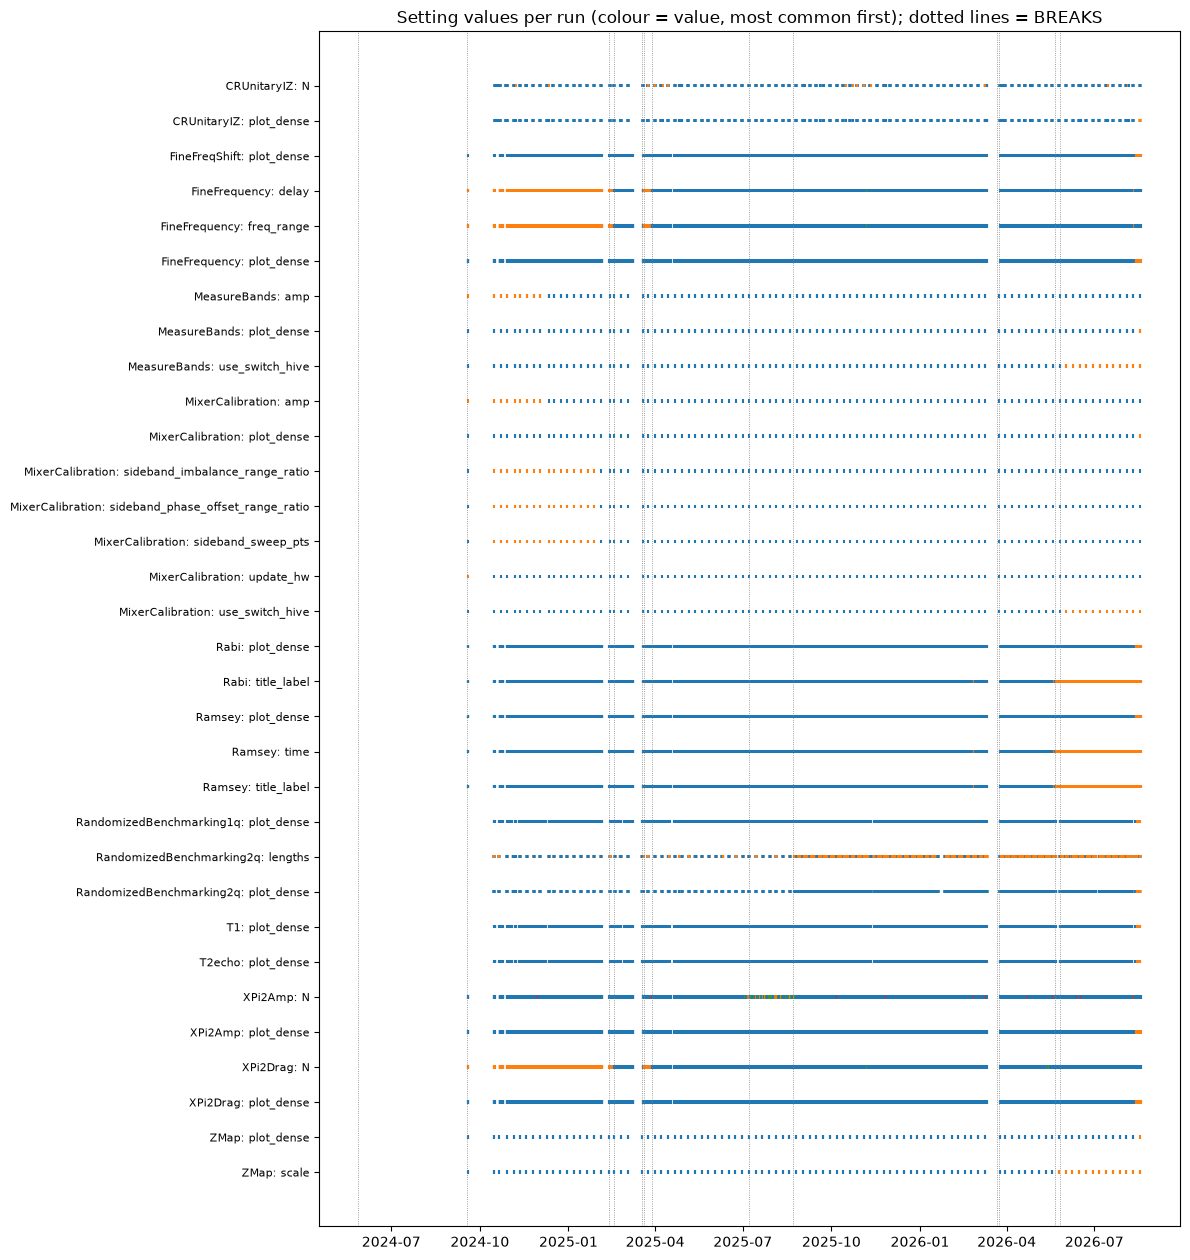

wrote data/derived/measurements/config_settings.parquet: 337663 rows, 40999 payloads, 141 type-field pairs


In [5]:
MATCH_DAYS = 2  # as in B3a, from the largest p95 gap between runs of a routine (41.81 h)
MD = pd.Timedelta(days=MATCH_DAYS)
st["prev_first"] = st.sort_values("first").groupby(["measurement_type", "measurement_name", "field"])["first"].shift()
ev = st[st["change"]].sort_values("first").groupby(["measurement_type", "field", "prev", "value"]).agg(
    names=("measurement_name", "nunique"), changes=("value", "size"), from_run=("prev_first", "first"),
    first=("first", "min"), last=("first", "max")).reset_index()
ev["window_d"] = ((ev["first"] - ev["from_run"]).dt.total_seconds() / 86400).round(3)


def window_break(lo: pd.Timestamp, hi: pd.Timestamp) -> tuple[str, float]:
    """The BREAKS entry within MATCH_DAYS of [lo, hi] nearest to hi, and hi minus its time in days."""
    hits = [b for b in periods.BREAKS if lo - MD <= b.at <= hi + MD]
    if not hits:
        return "", np.nan
    b = min(hits, key=lambda b: abs(hi - b.at))
    return b.what, round((hi - b.at).total_seconds() / 86400, 3)


ev[["break", "break_lag_d"]] = pd.DataFrame([window_break(lo, hi) for lo, hi in zip(ev["from_run"], ev["first"])],
                                            index=ev.index)


def git(repo: Path, *args: str) -> str:
    """Run git in a local clone and return its output; exit status 1 (no match) gives empty output."""
    p = subprocess.run(["git", "-C", repo, *args], capture_output=True, text=True)
    if p.returncode > 1 or (p.returncode == 1 and p.stderr):
        raise RuntimeError(p.stderr)
    return p.stdout.strip()


def window_commits(repo: Path, field: str, lo: pd.Timestamp, hi: pd.Timestamp) -> str:
    """Commits on any branch dated within MATCH_DAYS before lo to hi whose diff adds or removes a line with 'field' or field=."""
    out = git(repo, "log", "--all", f"--since={(lo - MD).isoformat()}", f"--until={hi.isoformat()}", "--format=%h %cs %s",
              "-G", rf"['\"]{field}['\"]|\b{field}\s*=").splitlines()
    return f"{len(out)}: " + " | ".join(c[:50] for c in out[:2]) if out else ""


for repo in (ROUTINES, MAAC):
    print(f"{repo.name}: latest commit on any branch {git(repo, 'log', '--all', '-1', '--format=%h %cs')}")
ev["routines_commits"] = [window_commits(ROUTINES, f, lo, hi) for f, lo, hi in zip(ev["field"], ev["from_run"], ev["first"])]
ev["maac_commits"] = [window_commits(MAAC, f, lo, hi) for f, lo, hi in zip(ev["field"], ev["from_run"], ev["first"])]
print(f"setting changes (a run's value differs from the same name's previous run), grouped by type, field and values. "
      f"The first change lies in [from_run, first]; break = the BREAKS entry within {MATCH_DAYS} days of that window, "
      f"commits = those dated from {MATCH_DAYS} days before from_run to first whose diff touches the field:")
display(ev.sort_values(["measurement_type", "field", "first"]).assign(
    prev=ev["prev"].str.slice(0, 40), value=ev["value"].str.slice(0, 40), from_run=ev["from_run"].dt.floor("s"),
    first=ev["first"].dt.floor("s"), last=ev["last"].dt.floor("s")).reset_index(drop=True))
print("routines HEAD lines that name the changed setting fields (calibration_routines/scripts):")
for fld in sorted(set(changed.get_level_values("field"))):
    hits = git(ROUTINES, "grep", "-n", "-E", rf"['\"]{fld}['\"]|\b{fld}\s*=|for {fld} in", "HEAD", "--",
               "calibration_routines/scripts").splitlines()
    print(f"  {fld}: {len(hits)} lines", *[h.removeprefix("HEAD:calibration_routines/scripts/")[:150] for h in hits[:6]],
          sep="\n    ")
june = ev[(ev["first"] >= "2026-05-01") & (ev["first"] < "2026-07-01")]
print("setting changes first seen 2026-05-01 to 2026-06-30 (B3a duration step at 2026-06):")
display(june[["measurement_type", "field", "prev", "value", "names", "changes", "first", "last"]])

rows_f = mix.assign(row=mix["measurement_type"] + ": " + mix["field"])
order = sorted(rows_f["row"].unique(), reverse=True)
fig, ax = plt.subplots(figsize=(12, 0.35 * len(order) + 1.5))
for y, row in enumerate(order):
    g = rows_f[rows_f["row"] == row]
    codes = g["value"].map({v: i for i, v in enumerate(g["value"].value_counts().index)})
    ax.scatter(g["first"], np.full(len(g), y), c=codes, cmap="tab10", vmin=0, vmax=9, s=6, marker="|")
for b in periods.BREAKS:
    ax.axvline(b.at, color="grey", lw=0.6, ls=":")
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set_title("Setting values per run (colour = value, most common first); dotted lines = BREAKS")
fig.tight_layout()
fig.savefig(FIG / "b3b_config_settings.png", dpi=150)
plt.show()

OUT.mkdir(parents=True, exist_ok=True)
settings = cfg.set_index(["measurement_type", "field"]).loc[setting].reset_index()[
    ["id", "measurement_type", "measurement_name", "time_start", "routine", "run_start", "field", "value"]]
settings.to_parquet(OUT / "config_settings.parquet", index=False)
print(f"wrote {OUT.relative_to(REPO_ROOT)}/config_settings.parquet: {len(settings)} rows, {settings['id'].nunique()} payloads, "
      f"{settings.groupby(['measurement_type', 'field']).ngroups} type-field pairs")

**Results.**
- The `calibrate_1q` breaks are the only clean match. The FineFrequency and XPi2Drag ladders change 0.002 to 0.009 d after "calibrate_1q code change" and "calibrate_1q old code back", in windows under 0.17 d.
- The other `BREAKS` hits are the DS1 restore, the 2025-02-12 outage end or DS2 and DS3 changes, not routine code - the DS1 restore, for one, sits 28 d before the MixerCalibration sideband change in a 27.6 d window, and the outage end closes the 97 d window of the CRUnitaryIZ `N` return to 2. The odd one out is `use_switch_hive`: DS2's last DC bias change lands in its 6.9 d window, just after the last `false` run. It could be the same switch, but we don't chase it here.
- Window commits are thin. The FineFrequency `delay` return on 2025-03-20 has maac 783d905d ("Qslam Integration") the same day, and most `plot_dense` windows have maac 72424b6c (2026-08-13). The 2025-02-17 ladder change, `use_switch_hive`, ZMap `scale` and the sideband changes have none, and the long CRUnitaryIZ and XPi2Amp `N` windows (9.980 to 97.047 d) just pick up 4 to 24 unrelated commits.
- At HEAD, `calibrate_1q.py` hard-codes the FineFrequency `delay` and XPi2Amp `N` ladders (lines 174 and 222), `benchmarking.py` passes both RB2q lists (lines 165 and 248), and `use_switch_hive` is `False` in `mixer_calibration.py` and `True` in `mixer_calibration_remote.py`. Nothing at HEAD names the sideband fields, `plot_dense`, `title_label` or `time`.
- Nothing in RB1q or RB2q changes in 2026-05/06 - only XPi2Drag `N` (one run), ZMap `scale` and `use_switch_hive` - so the config doesn't explain B3a's duration step.
- `config_settings.parquet` holds 337,663 rows over the 40,999 payloads and 141 settings.

### Ladders

The ladders need a closer look, since a run's ladder is built from its *claimed* payloads. We read the routines code that runs them, then set each run's ladder against every spine row of the name in that run (a row belongs to the latest run of its routine starting at or before it, within 6 h) and against the out-of-spec and revert warnings in `output_info`.

In [6]:
def show(repo: Path, path: str, spans: list[tuple[int, int]]) -> None:
    """Print numbered lines of a file at HEAD."""
    src = git(repo, "show", f"HEAD:{path}").splitlines()
    for a, b in spans:
        print(*[f"{Path(path).name}:{i}: {src[i - 1]}" for i in range(a, b + 1)], sep="\n")


show(ROUTINES, "calibration_routines/scripts/calibrate_1q.py", [(173, 190), (220, 240), (251, 265)])
show(ROUTINES, "calibration_routines/scripts/calibrate_2q.py", [(84, 96)])

# A run's ladder (section 1) is built from its claimed payloads. Put it beside every spine row of the name in the run.
LADDERS = {("FineFrequency", "delay"): "calibrate_1q", ("XPi2Amp", "N"): "calibrate_1q",
           ("XPi2Drag", "N"): "calibrate_1q", ("CRUnitaryIZ", "N"): "calibrate_2q"}
starts = load_run_map()[["routine", "start"]].drop_duplicates().astype({"start": "datetime64[ns]"}).sort_values("start")
spine = m[["id", "measurement_type", "measurement_name", "time_start"]].astype(
    {"time_start": "datetime64[ns]"}).sort_values("time_start")
lad = []
for (t, fld), routine in LADDERS.items():
    r = runs[(runs["measurement_type"] == t) & (runs["field"] == fld)]
    s = pd.merge_asof(spine[(spine["measurement_type"] == t) & spine["measurement_name"].isin(set(r["measurement_name"]))],
                      starts.loc[starts["routine"] == routine, ["start"]], left_on="time_start", right_on="start",
                      direction="backward", tolerance=pd.Timedelta("6h"))
    n = s.assign(claimed=s["id"].isin(claim.index)).groupby(["measurement_name", "start"]).agg(
        spine_rows=("id", "size"), claimed_rows=("claimed", "sum"))
    lad.append(r.join(n, on=["measurement_name", "run_start"]))
lad = pd.concat(lad).fillna({"spine_rows": 0, "claimed_rows": 0}).astype({"spine_rows": int, "claimed_rows": int})
print("runs per ladder (claimed payloads read) against the spine rows of the name in the run "
      "(latest start of the routine at or before the row, within 6 h) and how many of those are claimed:")
display(lad.groupby(["measurement_type", "field", "value", "spine_rows", "claimed_rows"]).agg(
    runs=("value", "size"), names=("measurement_name", "nunique"), first=("first", "min"), last=("first", "max")))

warn = pd.DataFrame([(start, routine, str(w)) for _, start, routine, oi in iter_files()
                     for w in oi.get("warnings") or []], columns=["run_start", "routine", "warning"])
amp = warn["warning"].str.extract(r"Amplitude calibration out of spec for Q(?P<q>\d+) with N=(?P<N>\d+)").join(
    warn["run_start"]).dropna()
short = lad.loc[(lad["measurement_type"] == "XPi2Amp") & (lad["value"] == "1 > 2 > 4"), "run_start"]
print("XPi2Amp 'out of spec ... with N=' warnings by N, all qubits, in the runs with an XPi2Amp ladder 1 > 2 > 4:",
      amp.loc[amp["run_start"].isin(short), "N"].value_counts().to_dict())

rev = warn["warning"].str.extract(r"Reverting calibration for \((?P<c>\d+), (?P<t>\d+)\) with N=(?P<N>\d+)").join(
    warn["run_start"]).dropna()
rev["measurement_name"] = "cr_u_C" + rev["c"] + "-T" + rev["t"]
cr1 = lad[(lad["measurement_type"] == "CRUnitaryIZ") & (lad["value"] == "1")].merge(
    rev.loc[rev["N"] == "2", ["run_start", "measurement_name"]].drop_duplicates().assign(revert_n2=True),
    how="left", on=["run_start", "measurement_name"])
cr1["revert_n2"] = cr1["revert_n2"].eq(True)
cr1["in_incident"] = periods.within(cr1["run_start"], *[i.period for i in periods.INCIDENTS])
print("CRUnitaryIZ runs with ladder 1: a 'Reverting calibration for (c, t) with N=2' warning for the pair, "
      "and inside a periods.INCIDENTS period:")
display(pd.crosstab(cr1["revert_n2"], cr1["in_incident"], margins=True))
print("of them, no N=2 revert warning and outside INCIDENTS:")
display(cr1.loc[~cr1["revert_n2"] & ~cr1["in_incident"], ["measurement_name", "run_start", "spine_rows", "claimed_rows"]])

calibrate_1q.py:173:         out_of_spec = []
calibrate_1q.py:174:         for delay in [0.1e-6, 0.25e-6, 0.5e-6]:
calibrate_1q.py:175:             try:
calibrate_1q.py:176:                 if not qs:
calibrate_1q.py:177:                     break
calibrate_1q.py:178:                 freq_range = 1 / 10 / delay
calibrate_1q.py:179:                 result = env.run_measurement(f'fine_freq_{key}', q=qs, delay=delay, freq_range=freq_range,
calibrate_1q.py:180:                                              plot=False, update_hw=False)
calibrate_1q.py:181:                 for q in qs:
calibrate_1q.py:182:                     data = result.data[f'Q{q}']
calibrate_1q.py:183:                     if abs(data.new_frequency - env.hardware_model.get_qubit(q).get_drive_channel().frequency) \
calibrate_1q.py:184:                             > freq_range / 2:
calibrate_1q.py:185:                         out_of_spec.append(q)
calibrate_1q.py:186:                         add_warning(f'Fine-frequency cal

runs per ladder (claimed payloads read) against the spine rows of the name in the run (latest start of the routine at or before the row, within 6 h) and how many of those are claimed:


runs  names                      first                       last
measurement_type field value                   spine_rows claimed_rows                                                                   
CRUnitaryIZ      N     1                       2          1               49     22 2024-11-07 18:58:41.253318 2026-08-17 09:05:15.397661
                       2                       1          1               95     32 2024-10-18 15:32:11.550480 2024-10-28 00:05:32.984085
                                               2          1             2815     34 2024-10-16 23:50:04.737031 2026-08-17 09:10:39.919616
                                               9          1                1      1 2025-09-03 09:07:54.307458 2025-09-03 09:07:54.307458
FineFrequency    delay 1e-07 > 2.5e-07         2          2              476      2 2024-09-18 15:16:46.199671 2026-08-11 08:52:44.437408
                                               3          2                1      1 2024-10-21 12:05:30.830841 2024-10-21 12:05:30.830841
                                               10         2                1      1 2025-02-17 08:02:39.859028 2025-02-17 08:02:39.859028
                                               12         2                1      1 2025-02-17 14:20:44.211466 2025-02-17 14:20:44.211466
                       1e-07 > 2.5e-07 > 5e-07 3          3             1997      2 2025-02-17 16:13:21.403109 2026-08-18 08:49:58.638250
                       2.5e-07 > 5e-07         2          2                1      1 2025-11-07 08:56:53.195262 2025-11-07 08:56:53.195262
XPi2Amp          N     1 > 2                   2          2                1      1 2026-08-10 13:47:26.169116 2026-08-10 13:47:26.169116
                       1 > 2 > 4               3          3                1      1 2026-05-19 08:55:16.378714 2026-05-19 08:55:16.378714
                                               4          3               21      2 2024-09-18 16:31:31.588489 2026-07-02 08:53:34.894482
                       1 > 2 > 4 > 8           4          4             2346      2 2024-09-18 15:35:01.344707 2026-08-18 08:55:05.191631
                                               8          4                1      1 2025-02-17 08:05:43.192162 2025-02-17 08:05:43.192162
                                               9          4                2      1 2024-10-21 12:09:25.503663 2025-02-17 14:23:49.419634
                       4                       1          1                1      1 2024-09-18 15:33:39.904770 2024-09-18 15:33:39.904770
                       4 > 8                   2          2               28      1 2025-07-03 19:54:14.777498 2025-08-24 08:55:32.042364
                       8                       1          1               35      1 2025-07-03 08:55:45.595970 2025-08-23 19:54:23.125052
XPi2Drag         N     1 > 2 > 4               3          3              475      2 2024-09-18 15:38:50.875991 2025-03-28 08:58:28.324132
                                               5          3                1      1 2024-10-21 12:17:09.442760 2024-10-21 12:17:09.442760
                                               8          3                1      1 2025-02-17 08:11:23.701796 2025-02-17 08:11:23.701796
                                               15         3                1      1 2025-02-17 14:29:32.467220 2025-02-17 14:29:32.467220
                       2 > 3                   2          2                3      2 2025-11-07 09:22:33.307746 2026-05-15 08:59:51.248504
                                               3          2                1      1 2026-07-02 08:57:18.665610 2026-07-02 08:57:18.665610
                       2 > 3 > 4               3          3             1984      2 2025-02-17 16:23:25.511520 2026-08-18 08:59:51.362471
                       3 > 4                   2          2                1      1 2026-05-18 08:50:14.150568 2026-05-18 08:50:14.150568

XPi2Amp 'out of spec ... with N=' warnings by N, all qubits, in the runs with an XPi2Amp ladder 1 > 2 > 4: {'8': 221, '4': 118, '1': 51, '2': 44}
CRUnitaryIZ runs with ladder 1: a 'Reverting calibration for (c, t) with N=2' warning for the pair, and inside a periods.INCIDENTS period:


in_incident,False,True,All
revert_n2,,,
False,9,17,26
True,23,0,23
All,32,17,49


of them, no N=2 revert warning and outside INCIDENTS:


,measurement_name,run_start,spine_rows,claimed_rows
1,cr_u_C24-T23,2024-12-11 08:22:31,2,1
2,cr_u_C7-T16,2025-02-17 08:17:59,2,1
3,cr_u_C24-T23,2025-03-23 20:02:01,2,1
4,cr_u_C24-T23,2025-03-24 20:01:57,2,1
5,cr_u_C24-T23,2025-03-31 20:03:13,2,1
7,cr_u_C24-T23,2025-04-09 09:04:27,2,1
8,cr_u_C24-T23,2025-04-14 20:01:48,2,1
35,cr_u_C22-T18,2026-03-24 16:08:58,2,1
48,cr_u_C17-T16,2026-08-17 09:03:21,2,1


**Results.**
- The code explains the ladders. In `calibrate_1q.py` an out-of-spec qubit gets a warning and drops out of the later steps, and a step's id is only stored for in-spec qubits (lines 186–190, 233–240, 261–265). `calibrate_2q.py` reverts a pair when `abs(cr.scale * pulse['amp']) >= 1.0` and otherwise stores that step's id, so a reverted pair keeps the earlier one (lines 91–96).
- So a short ladder is mostly a fit outcome. FineFrequency and XPi2Drag claim every step they ran, and their odd ladders are runs with only 2 spine rows (one XPi2Drag run has 3). In 21 of the 22 XPi2Amp `1 > 2 > 4` runs the N=8 step ran but wasn't claimed, and those runs are full of out-of-spec warnings (221 at N=8).
- The one-name XPi2Amp `8` and `4 > 8` runs have just 1 or 2 spine rows - the earlier steps have no row at all.
- Every CRUnitaryIZ `N` = 1 run has 2 spine rows and 1 claim, so the N=2 step ran but wasn't kept. 23 of the 49 carry an N=2 revert warning; of the other 26, 17 are inside `INCIDENTS` and 9 aren't (6 of them cr_u_C24-T23, 2024-12 to 2025-04).

### RB2q lengths

RB2q `lengths` is the odd setting out, mixed in every month. We read the code that picks the list, split the payloads by fetch list and month, and check them against the DS3 KPI cell each one feeds (and whether its run has a DS3 run at all, via A3) and the pair's DS2 coupling quality in force at the payload's start.

In [7]:
show(ROUTINES, "calibration_routines/scripts/benchmarking.py", [(244, 249), (268, 273)])
rb = cfg[(cfg["measurement_type"] == "RandomizedBenchmarking2q") & (cfg["field"] == "lengths")].join(
    cl.set_index("id")["list"], on="id")
rb["lengths"] = np.where(rb["value"].str.contains("15, 20"), "long", "short")
print("RB2q lengths lists read:", rb.groupby("lengths")["value"].unique().to_dict())
print("RB2q payloads read, by B3a fetch list, lengths list and month:")
display(pd.crosstab(rb["time_start"].dt.to_period("M"), [rb["list"], rb["lengths"]]))

kpi = load_kpi_l2().dropna(subset=["result_id"]).drop_duplicates(["result_id", "metric"])
x = rb.merge(kpi[["result_id", "metric", "value_source", "value_status"]], left_on="id", right_on="result_id", how="left")
x = x.merge(load_run_map()[["routine", "start", "ds3_created_at"]].drop_duplicates()
            .rename(columns={"start": "run_start"}), on=["routine", "run_start"], how="left")
x["ds3_run"] = np.where(x["ds3_created_at"].notna(), "DS3 run", "no DS3 run")
print("RB2q payloads read, by fetch list, against whether their benchmarking run has a DS3 run (A3 link) "
      "and the DS3 Level-2 KPI cell whose result_id they are:")
display(pd.crosstab([x["ds3_run"], x["metric"].fillna("none"), x["value_source"].fillna("none"),
                     x["value_status"].fillna("none")], x["list"], margins=True))
print("runs with no DS3 run among them:", x.loc[x["ds3_run"] == "no DS3 run", "run_start"].nunique())

q = load_values()
q = q[q["path_template"].astype(str).str.endswith(".quality")]
q = q.join(q["entity_id"].astype(str).str.extract(r"\((?P<c>\d+), (?P<t>\d+)\)"))[["c", "t", "value_int", "valid_from_ts"]]
q["valid_from_ts"] = q["valid_from_ts"].astype("datetime64[ns]")
rb = rb.join(rb["measurement_name"].str.extract(r"C(?P<c>\d+)-T(?P<t>\d+)"))
rb["t0"] = rb["time_start"].astype("datetime64[ns]")
j = pd.merge_asof(rb.sort_values("t0"), q.sort_values("valid_from_ts"), left_on="t0", right_on="valid_from_ts",
                  by=["c", "t"], direction="backward")
j["quality"] = np.select([j["value_int"].isna(), j["value_int"] < 92], ["no DS2 value", "quality < 92"], "quality >= 92")
print(f"DS2 coupling quality rows {len(q)}, first valid_from {q['valid_from_ts'].min()}; RB2q payloads read {len(j)}, "
      f"names parsed to a coupling {rb['c'].notna().sum()}")
print("RB2q payloads read, by lengths list and the pair's DS2 quality in force at the payload's time_start:")
display(pd.crosstab(j["lengths"], j["quality"], margins=True))

benchmarking.py:244:             continue
benchmarking.py:245:         try:
benchmarking.py:246:             coupling_qualities = [env.get_coupling(c, t).quality for c, t in q_pair_group]
benchmarking.py:247:             if any([quality < 92 for quality in coupling_qualities]):
benchmarking.py:248:                 result = env.measurements[f'rb2q_{group_name}'](plot=False, lengths=np.array(range(1, 15, 1)))
benchmarking.py:249:             else:
benchmarking.py:268:                 fit_error['fidelities_2q'][f'C{c}-T{t}'] = error
benchmarking.py:269: 
benchmarking.py:270:                 if fit_quality['fidelities_2q'][f'C{c}-T{t}'] > 0.8:
benchmarking.py:271:                     env.get_coupling(c, t).quality = int(benchmarks['fidelities_2q'][f'C{c}-T{t}'] * 100)
benchmarking.py:272:                 else:
benchmarking.py:273:                     env.get_coupling(c, t).quality = 50
RB2q lengths lists read: {'long': <ArrowStringArray>
['[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 30, 40, 60

list       coherence_rb       local before B3a      
lengths            long short             long short
time_start                                          
2024-10              66    30                0     0
2024-11             104    22                0     0
2024-12             128    25                0     0
2025-01              96    24                0     0
2025-02              88    34                0     0
2025-03             100    24                0     0
2025-04              94    32                0     0
2025-05              98    30                0     0
2025-06             127    33                0     0
2025-07              96    29                0     0
2025-08              94    30                2    20
2025-09             124    33                0    81
2025-10             101    25                1    83
2025-11              96    30                1    64
2025-12             123    32                0    79
2026-01             100    24                0    69
2026-02             101    25                0    67
2026-03              95    26                3    77
2026-04              77    32               13   147
2026-05              85    20                7    82
2026-06             106    25                6    82
2026-07              79    28                9    72
2026-08              51    27                7    43

RB2q payloads read, by fetch list, against whether their benchmarking run has a DS3 run (A3 link) and the DS3 Level-2 KPI cell whose result_id they are:


list                                         coherence_rb  local before B3a   All
ds3_run    metric value_source value_status                                      
DS3 run    fCX    ds1          low_r2                   0              1015  1015
                  none         no_fit                   3                 0     3
                  output_info  low_r2                  62                 0    62
                  qcaas        low_r2                  12                 0    12
                               no_r2                    1                 0     1
                               ok                    2481                 0  2481
no DS3 run none   none         none                   310                 0   310
All                                                  2869              1015  3884

runs with no DS3 run among them: 25


DS2 coupling quality rows 8909, first valid_from 2025-01-01 08:00:13; RB2q payloads read 3884, names parsed to a coupling 3884
RB2q payloads read, by lengths list and the pair's DS2 quality in force at the payload's time_start:


quality,no DS2 value,quality < 92,quality >= 92,All
lengths,,,,
long,298,0,1980,2278
short,77,1529,0,1606
All,375,1529,1980,3884


**Results.**
- `benchmarking.py` runs the short list when any pair in the group has quality below 92 (lines 247–248), and sets that quality to `int(fidelity * 100)` from the last fit, or 50 when the fit is poor (lines 270–273).
- The data follow it exactly: all 1,529 short-list payloads had DS2 quality < 92 at their start and all 1,980 long-list ones ≥ 92 (375 have no DS2 value). So the list is picked by the previous fCX, and a contrast between lists carries the previous fidelity.
- The weekly `coherence_rb` sample is steady (20–34 short and 51–128 long a month). The 1,015 payloads local before B3a are all DS3 `ds1` `low_r2` fCX cells - rejects - which is why the short list jumps from 2025-09.
- Of the 2,869 `coherence_rb` payloads, the 310 with no KPI cell all sit in 25 benchmarking runs with no DS3 run. That's B4's run-level gap, not a join loss.

### Regimes and blocks

Last, two checks on the regimes. We count the FineFrequency and XPi2Drag ladders per `periods.segment` between the three `calibrate_1q` `BREAKS` entries, and find the blocks of consecutive runs with Ramsey `time` and the Rabi and Ramsey `title_label`.

In [8]:
b1q = [b for b in periods.BREAKS if b.what.startswith("calibrate_1q")]
print("calibrate_1q BREAKS entries:", *[f"{b.at} {b.what}" for b in b1q], sep="\n  ")
seg = lad[lad["measurement_type"].isin(["FineFrequency", "XPi2Drag"])].copy()
seg["segment"] = periods.segment(seg["run_start"], b1q)
print("FineFrequency and XPi2Drag runs per ladder between the calibrate_1q BREAKS entries "
      "(segment = entries at or before the run), with spine and claimed rows as above:")
display(seg.groupby(["measurement_type", "segment", "value", "spine_rows", "claimed_rows"]).agg(
    runs=("value", "size"), first=("run_start", "min"), last=("run_start", "max")))

print("runs by presence of the field in their payloads, in blocks of consecutive runs, from 2026-01-01:")
for t, fld in [("Ramsey", "time"), ("Ramsey", "title_label"), ("Rabi", "title_label")]:
    g = cfg[(cfg["measurement_type"] == t) & (cfg["field"] == fld)]
    pres = (g.assign(present=g["value"].ne("<absent>")).groupby("run_start")["present"]
            .agg(in_all="min", in_any="max").reset_index())
    pres["block"] = pres["in_any"].ne(pres["in_any"].shift()).cumsum()
    blocks = pres.groupby("block").agg(present=("in_any", "first"), in_all=("in_all", "min"), runs=("run_start", "size"),
                                       first=("run_start", "min"), last=("run_start", "max"))
    print(f"{t}: {fld}")
    display(blocks[blocks["last"] >= "2026-01-01"].reset_index(drop=True))

calibrate_1q BREAKS entries:
  2025-02-17 16:11:02 calibrate_1q code change
  2025-03-20 12:00:58 calibrate_1q old code back
  2025-03-28 19:44:15 calibrate_1q new code back
FineFrequency and XPi2Drag runs per ladder between the calibrate_1q BREAKS entries (segment = entries at or before the run), with spine and claimed rows as above:


runs               first                last
measurement_type segment value                   spine_rows claimed_rows                                              
FineFrequency    0       1e-07 > 2.5e-07         2          2              439 2024-09-18 15:13:54 2025-02-17 14:18:25
                                                 3          2                1 2024-10-21 12:02:39 2024-10-21 12:02:39
                                                 10         2                1 2025-02-17 08:00:21 2025-02-17 08:00:21
                                                 12         2                1 2025-02-17 14:18:25 2025-02-17 14:18:25
                 1       1e-07 > 2.5e-07 > 5e-07 3          3               80 2025-02-17 16:11:02 2025-03-20 08:00:20
                 2       1e-07 > 2.5e-07         2          2               36 2025-03-20 12:00:58 2025-03-28 08:45:22
                 3       1e-07 > 2.5e-07         2          2                1 2026-08-11 08:45:42 2026-08-11 08:45:42
                         1e-07 > 2.5e-07 > 5e-07 3          3             1917 2025-03-28 19:44:15 2026-08-18 08:45:39
                         2.5e-07 > 5e-07         2          2                1 2025-11-07 08:45:16 2025-11-07 08:45:16
XPi2Drag         0       1 > 2 > 4               3          3              439 2024-09-18 15:13:54 2025-02-17 14:18:25
                                                 5          3                1 2024-10-21 12:02:39 2024-10-21 12:02:39
                                                 8          3                1 2025-02-17 08:00:21 2025-02-17 08:00:21
                                                 15         3                1 2025-02-17 14:18:25 2025-02-17 14:18:25
                 1       2 > 3 > 4               3          3               80 2025-02-17 16:11:02 2025-03-20 08:00:20
                 2       1 > 2 > 4               3          3               36 2025-03-20 12:00:58 2025-03-28 08:45:22
                 3       2 > 3                   2          2                3 2025-11-07 08:45:16 2026-05-15 08:45:17
                                                 3          2                1 2026-07-02 08:45:41 2026-07-02 08:45:41
                         2 > 3 > 4               3          3             1904 2025-03-28 19:44:15 2026-08-18 08:45:39
                         3 > 4                   2          2                1 2026-05-18 08:45:17 2026-05-18 08:45:17

runs by presence of the field in their payloads, in blocks of consecutive runs, from 2026-01-01:
Ramsey: time


,present,in_all,runs,first,last
0,False,False,934,2024-09-18 15:13:54,2026-02-25 08:45:16
1,True,True,2,2026-02-25 20:42:06,2026-02-26 08:45:36
2,False,False,134,2026-02-26 19:42:26,2026-05-19 08:45:16
3,True,True,1,2026-05-20 08:45:38,2026-05-20 08:45:38
4,False,False,2,2026-05-20 21:34:10,2026-05-21 08:46:12
5,True,True,4,2026-05-21 20:26:57,2026-05-25 08:45:38
6,False,False,2,2026-05-25 22:04:48,2026-05-26 08:45:17
7,True,True,166,2026-05-26 19:38:12,2026-08-18 08:45:39


Ramsey: title_label


,present,in_all,runs,first,last
0,False,False,934,2024-09-18 15:13:54,2026-02-25 08:45:16
1,True,True,2,2026-02-25 20:42:06,2026-02-26 08:45:36
2,False,False,134,2026-02-26 19:42:26,2026-05-19 08:45:16
3,True,True,1,2026-05-20 08:45:38,2026-05-20 08:45:38
4,False,False,2,2026-05-20 21:34:10,2026-05-21 08:46:12
5,True,True,4,2026-05-21 20:26:57,2026-05-25 08:45:38
6,False,False,2,2026-05-25 22:04:48,2026-05-26 08:45:17
7,True,True,166,2026-05-26 19:38:12,2026-08-18 08:45:39


Rabi: title_label


,present,in_all,runs,first,last
0,False,False,934,2024-09-18 15:13:54,2026-02-25 08:45:16
1,True,True,2,2026-02-25 20:42:06,2026-02-26 08:45:36
2,False,False,134,2026-02-26 19:42:26,2026-05-19 08:45:16
3,True,True,1,2026-05-20 08:45:38,2026-05-20 08:45:38
4,False,False,2,2026-05-20 21:34:10,2026-05-21 08:46:12
5,True,True,4,2026-05-21 20:26:57,2026-05-25 08:45:38
6,False,False,2,2026-05-25 22:04:48,2026-05-26 08:45:17
7,True,True,166,2026-05-26 19:38:12,2026-08-18 08:45:39


**Results.**
- Each segment runs a single ladder pair - `1e-07 > 2.5e-07` with `1 > 2 > 4` in segments 0 and 2, and the three-step pair in 1 and 3 - apart from 2 FineFrequency and 5 XPi2Drag partial runs in segment 3.
- Ramsey `time` and both `title_label`s switch on and off together, a whole run at a time: in 7 runs between 2026-02-25 and 05-25, then in every run from 2026-05-26 19:38:12.

## Conclusion

| Result | Status |
|---|---|
| Every local payload (40,999) decodes and matches its spine row | Configs join by `id` |
| 141 settings, 32 of which change | Per payload in `config_settings.parquet` |
| RB2q, CRUnitaryIZ, ZMap and the mixer types are weekly samples | Their change dates are good to a week |
| FineFrequency and XPi2Drag ladders change with the `calibrate_1q` breaks, one pair per segment | Stratify by `periods.segment`, not by the run's ladder |
| Other short ladders are fit outcomes - out-of-spec qubits drop out and their steps go unclaimed | A payload's own `N` or `delay` is its stratum |
| CRUnitaryIZ `N` = 1 is a reverted N=2 step (or an incident) | A 2q stratum, not a setting |
| XPi2Amp `8` / `4 > 8` on one name, 2025-07-03 to 08-24 | A B3c stratum |
| The RB2q list is picked by the previous fCX fit | Stratify by list; a list contrast isn't an effect; count from `coherence_rb` |
| RB2q payloads with no KPI cell all sit in runs with no DS3 run | B4's gap, not a join loss |
| MixerCalibration sideband settings 2024-10-16 to 2025-01-27; `use_switch_hive` from 2026-06-01 | Strata if mixer results are used |
| No RB config change in 2026-05/06 | B3a's duration step isn't a config change |
| Ramsey `time` in every run from 2026-05-26, and 7 runs before | B3c checks the sweep per payload |
| No routine cause for the other changes | Open |